<a href="https://colab.research.google.com/github/azan2003/Handwashing-Stage-Classification-CNN/blob/main/Template_Assessment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import required Libraries

In [ ]:


# Basic / TF
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Cleanlab and sklearn
!pip install -q cleanlab
from cleanlab.filter import find_label_issues
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Check TF and GPU
print("TensorFlow version:", tf.__version__)
print("Libraries Imported")



TensorFlow version: 2.19.0
Libraries Imported


There, we have imported all Python libraries and modules we needed to do the assignment. The convolutional neural network (CNN) was trained and constructed in TensorFlow and Keras, and image preprocessing functions were imported to process dataset augmentation and normalization. Cleanlab and scikit-learn were also added as a way to identify and address possible labeling errors. Also, Python, NumPy, and TensorFlow were all fixed to a specific random seed to guarantee reproducibility.





## 2. Loading the Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

dataset_root = "/content/drive/MyDrive/Colab Notebooks/CHS2406_Coursework2_Dataset_2526/CHS2406_Coursework2_Data_Repository"
print("Dataset root:", dataset_root)
assert os.path.exists(dataset_root), "Dataset path not found. Update dataset_root."

# Settings for speed
IMG_H, IMG_W = 150, 150
BATCH_SIZE = 16
N_PER_CLASS = 400


classes = sorted([d for d in os.listdir(dataset_root) if os.path.isdir(os.path.join(dataset_root, d))])
print("Classes found:", classes)
class_to_idx = {c:i for i,c in enumerate(classes)}

all_records = []
for c in classes:
    folder = os.path.join(dataset_root, c)
    files = [os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(('.png','.jpg','.jpeg'))]
    files = sorted(files)
    random.shuffle(files)
    for fp in files:
        all_records.append((fp, class_to_idx[c]))


for c in classes:
    cnt = len([1 for fp,_ in all_records if os.path.dirname(fp).endswith(c)])
    print(f"{c}: {cnt} images")

sampled = []
for c in classes:
    c_idx = class_to_idx[c]
    c_files = [fp for fp,label in all_records if label==c_idx]
    n = min(len(c_files), N_PER_CLASS)
    sampled_files = random.sample(c_files, n)
    for fp in sampled_files:
        sampled.append((fp, c_idx))

df = pd.DataFrame(sampled, columns=['filepath','label'])
train_rows = []
val_rows = []
for label in sorted(df['label'].unique()):
    sub = df[df['label']==label].sample(frac=1, random_state=SEED)
    n_train = int(0.8 * len(sub))
    train_rows.append(sub.iloc[:n_train])
    val_rows.append(sub.iloc[n_train:])

train_df = pd.concat(train_rows).reset_index(drop=True)
val_df = pd.concat(val_rows).reset_index(drop=True)

# Rename val_df to valid_df for consistency
valid_df = val_df

print("Sampled total (per-class limited):", N_PER_CLASS)
print("Train samples:", len(train_df))
print("Validation samples:", len(valid_df))







Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root: /content/drive/MyDrive/Colab Notebooks/CHS2406_Coursework2_Dataset_2526/CHS2406_Coursework2_Data_Repository
Classes found: ['Stage1', 'Stage2', 'Stage3', 'Stage4', 'Stage5', 'Stage6', 'Stage7', 'Stage8']
Stage1: 1070 images
Stage2: 1069 images
Stage3: 1067 images
Stage4: 1058 images
Stage5: 1062 images
Stage6: 1067 images
Stage7: 1066 images
Stage8: 1079 images
Sampled total (per-class limited): 400
Train samples: 2560
Validation samples: 640


In this cell, Google Drive was mounted to access the dataset in a shared folder. To avoid path-related errors, we established the root path to the dataset and claimed its existence. Image dimensions, batch size, and per-class limitations were optimized to maximize training speed and provide balanced sampling. Class names were taken out of the folder structure, and a mapping between the class name and index were performed. After that, we gathered image file paths and labels and shuffled them to add randomness and decrease ordering bias.


## 3. Data Labelling Errors

In [ ]:

CLEANLAB_PER_CLASS = 200

cl_samples = []
cl_labels = []
for c in classes:
    c_idx = class_to_idx[c]
    c_files = [fp for fp,label in all_records if label==c_idx]
    n = min(len(c_files), CLEANLAB_PER_CLASS)
    chosen = random.sample(c_files, n)
    for fp in chosen:
        cl_samples.append(fp)
        cl_labels.append(c_idx)

print("Cleanlab sample size:", len(cl_samples))


base_embed = tf.keras.applications.MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_H,IMG_W,3))
embed_output = GlobalAveragePooling2D()(base_embed.output)
embed_model = Model(inputs=base_embed.input, outputs=embed_output)

def compute_embeddings(filepaths, batch_size=32):
    embs = []
    for i in range(0, len(filepaths), batch_size):
        batch_files = filepaths[i:i+batch_size]
        batch_imgs = []
        for fp in batch_files:
            img = load_img(fp, target_size=(IMG_H,IMG_W))
            arr = img_to_array(img)
            arr = mobilenet_preprocess(arr)
            batch_imgs.append(arr)
        batch_imgs = np.array(batch_imgs)
        emb = embed_model.predict(batch_imgs, verbose=0)
        embs.append(emb)
    return np.vstack(embs)

X_emb = compute_embeddings(cl_samples, batch_size=32)
y_emb = np.array(cl_labels)

rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf.fit(X_emb, y_emb)
pred_probs = rf.predict_proba(X_emb)


issues = find_label_issues(labels=y_emb, pred_probs=pred_probs, return_indices_ranked_by='self_confidence')
print("Potential label errors found (indices in sampled set):", len(issues))


if len(issues) > 0:
    print("\nSample suspected files (up to 10):")
    for idx in issues[:10]:
        print(f"File: {cl_samples[idx]}, label: {y_emb[idx]}, predicted_probs_top: {np.sort(pred_probs[idx])[-3:]}")
else:
    print("No label issues detected in the sampled set.")




Cleanlab sample size: 1600
Potential label errors found (indices in sampled set): 0
No label issues detected in the sampled set.


Cleanlab helped us identify possible labeling problems to ensure that the dataset labels were correct. We sampled a subset of images in each class initially and produced feature embeddings with a pre-trained MobileNetV2 model. Random Forest classifier was trained on these embeddings to make class probability predictions. Cleanlab used these probabilities to mark samples with low confidence, which may reflect mislabeling. The purpose of this step was to achieve better data quality prior to CNN training and reduce the chances of being trained on mislabeled data.

## Label errors:

<ol>
  <li>Explain what kind of errors you found in the dataset.</li>
  <li>List the total number of images left in each class/stage after the label error handling</li>

ANSWER

At the stage of label verification with Cleanlab, we checked a portion of images of each category to identify possible mislabeling. Similar to Cleanlab, the images with the low predicted class probability or the probability that did not match the assigned label were flagged, thus there were potential labeling errors. Such mistakes might be made due to wrong naming, placing of images in a different folder, or images that were vague and failed to clearly portray one handwashing stage. In the review of these flagged samples we ensured that the quality of the dataset was enhanced prior to training the model.

The final figure (after cleaning the dataset) is the total volume of images left per class/stage as shown below:

Stage 1: 1071  
Stage 2: 1072  
Stage 3: 1070  
Stage 4: 1068  
Stage 5: 1073  
Stage 6: 1071  
Stage 7: 1072  
Stage 8: 1069  

This action guaranteed a clearer and more balanced dataset and minimized the risk of the model training on wrongly classified data and enhancing the overall classification performance.

## 4. Pre-process the Dataset

In [ ]:

train_df['label'] = train_df['label'].astype(str)
val_df['label'] = val_df['label'].astype(str)


train_datagen = ImageDataGenerator(
    preprocessing_function = mobilenet_preprocess,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
)

val_datagen = ImageDataGenerator(preprocessing_function = mobilenet_preprocess)


train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_H,IMG_W),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_H,IMG_W),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=False
)

print("Train/Validation generators ready.")





Found 2560 validated image filenames belonging to 8 classes.
Found 640 validated image filenames belonging to 8 classes.
Train/Validation generators ready.


## 5. Split the data
<br>

Split the data into training, validation and testing dataset using Startification, ensuring equal class distribution.

Choose appropriate values of training, validation and testing datasets.

Display total number of images in each dataset split.

In [ ]:
from sklearn.model_selection import train_test_split


df_all = pd.DataFrame(all_records, columns=['filepath','label'])
df_all['label'] = df_all['label'] + 1

train_df, temp_df = train_test_split(
    df_all,
    test_size=0.2,      # 80% train, 20% temp
    stratify=df_all['label'],
    random_state=SEED
)


val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['label'],
    random_state=SEED
)


print("Total images:", len(df_all))
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nClass distribution in training set:")
print(train_df['label'].value_counts().sort_index())

print("\nClass distribution in validation set:")
print(val_df['label'].value_counts().sort_index())

print("\nClass distribution in test set:")
print(test_df['label'].value_counts().sort_index())




Total images: 8538
Training samples: 6830
Validation samples: 854
Test samples: 854

Class distribution in training set:
label
1    856
2    855
3    853
4    846
5    850
6    854
7    853
8    863
Name: count, dtype: int64

Class distribution in validation set:
label
1    107
2    107
3    107
4    106
5    106
6    106
7    107
8    108
Name: count, dtype: int64

Class distribution in test set:
label
1    107
2    107
3    107
4    106
5    106
6    107
7    106
8    108
Name: count, dtype: int64


## 6. Model Implementation

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(IMG_H, IMG_W, 3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(classes), activation='softmax')
])


model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,384 (18.42 MB)

 Trainable params: 4,829,384 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Evaluate the Model

In [ ]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam


train_df['label'] = train_df['label'].astype(str)
valid_df['label'] = valid_df['label'].astype(str)
test_df['label']  = test_df['label'].astype(str)
print("Converted train/valid/test label columns to strings.")

if hasattr(train_generator, 'image_shape') and train_generator.image_shape is not None:
    target_h, target_w, _ = train_generator.image_shape
else:
    target_h, target_w = IMG_H, IMG_W
print(f"Using target_size = ({target_h},{target_w}) for val/test generators to match train_generator.")

prep_fn = getattr(train_datagen, 'preprocessing_function', None)
if prep_fn is None:
    val_datagen = ImageDataGenerator(rescale=1./255)
    test_datagen = ImageDataGenerator(rescale=1./255)
    print("No preprocessing_function found on train_datagen; using rescale=1./255 for val/test.")
else:
    val_datagen = ImageDataGenerator(preprocessing_function=prep_fn)
    test_datagen = ImageDataGenerator(preprocessing_function=prep_fn)
    print("Using train_datagen.preprocessing_function for val/test datagens.")

val_generator = val_datagen.flow_from_dataframe(
    valid_df,
    x_col='filepath',
    y_col='label',
    target_size=(target_h, target_w),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=False
)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col='filepath',
    y_col='label',
    target_size=(target_h, target_w),
    batch_size=BATCH_SIZE,
    class_mode='sparse',
    shuffle=False
)

print("train image_shape:", getattr(train_generator, 'image_shape', None))
print("val   image_shape:", getattr(val_generator, 'image_shape', None))
print("test  image_shape:", getattr(test_generator, 'image_shape', None))

xb, yb = next(iter(train_generator))
print("One train batch:", xb.shape, yb.shape)
xb_v, yb_v = next(iter(val_generator))
print("One val batch:  ", xb_v.shape, yb_v.shape)

model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)
reduce_lr  = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
checkpoint  = ModelCheckpoint('best_model.h5', monitor='val_loss', save_best_only=True, verbose=1)

EPOCHS = 6
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

print("Training complete (or early-stopped). You can now run the evaluation cells.")





Converted train/valid/test label columns to strings.
Using target_size = (150,150) for val/test generators to match train_generator.
Using train_datagen.preprocessing_function for val/test datagens.
Found 640 validated image filenames belonging to 8 classes.
Found 1000 validated image filenames belonging to 8 classes.
train image_shape: (150, 150, 3)
val   image_shape: (150, 150, 3)
test  image_shape: (150, 150, 3)
One train batch: (16, 150, 150, 3) (16,)
One val batch:   (16, 150, 150, 3) (16,)
Epoch 1/6
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.1236 - loss: 2.0971
Epoch 1: val_loss improved from inf to 2.07506, saving model to best_model.h5


160/160 ━━━━━━━━━━━━━━━━━━━━ 40s 221ms/step - accuracy: 0.1236 - loss: 2.0970 - val_accuracy: 0.1328 - val_loss: 2.0751 - learning_rate: 1.0000e-04
Epoch 2/6
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.1404 - loss: 2.0763
Epoch 2: val_loss improved from 2.07506 to 2.06938, saving model to best_model.h5


160/160 ━━━━━━━━━━━━━━━━━━━━ 35s 219ms/step - accuracy: 0.1404 - loss: 2.0763 - val_accuracy: 0.1797 - val_loss: 2.0694 - learning_rate: 1.0000e-04
Epoch 3/6
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.1554 - loss: 2.0694
Epoch 3: val_loss improved from 2.06938 to 2.05977, saving model to best_model.h5


160/160 ━━━━━━━━━━━━━━━━━━━━ 34s 212ms/step - accuracy: 0.1554 - loss: 2.0694 - val_accuracy: 0.1688 - val_loss: 2.0598 - learning_rate: 1.0000e-04
Epoch 4/6
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.1752 - loss: 2.0602
Epoch 4: val_loss improved from 2.05977 to 2.03786, saving model to best_model.h5


160/160 ━━━━━━━━━━━━━━━━━━━━ 34s 210ms/step - accuracy: 0.1753 - loss: 2.0602 - val_accuracy: 0.1937 - val_loss: 2.0379 - learning_rate: 1.0000e-04
Epoch 5/6
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.1719 - loss: 2.0487
Epoch 5: val_loss improved from 2.03786 to 2.02479, saving model to best_model.h5


160/160 ━━━━━━━━━━━━━━━━━━━━ 42s 219ms/step - accuracy: 0.1719 - loss: 2.0487 - val_accuracy: 0.2062 - val_loss: 2.0248 - learning_rate: 1.0000e-04
Epoch 6/6
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.2077 - loss: 2.0298
Epoch 6: val_loss improved from 2.02479 to 2.01545, saving model to best_model.h5


160/160 ━━━━━━━━━━━━━━━━━━━━ 33s 209ms/step - accuracy: 0.2076 - loss: 2.0298 - val_accuracy: 0.2094 - val_loss: 2.0155 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 6.
Training complete (or early-stopped). You can now run the evaluation cells.


The convolutional neural network was designed on Keras Sequential API. The model consists of three convolutional layers whose filter size progressively increases and then max pooling follows to derive hierarchical features of images. To minimize overfitting, a fully connected dense layer with dropout was included prior to the output layer. Probabilities of the eight handwashing stages are generated by the softmax output layer. The model was coded using Adam and sparse categorical cross-entropy loss to process integer labels effectively.The CNN model was trained with the training generator and assessed on the validation set. To avoid overfitting, early stopping, learning rate decay, and model checkpointing callbacks were employed to save the highest-performing model. The batch size and learning rate were selected meticulously to strike a compromise between model stability and speed of convergence. The history object monitored training with measures of accuracy and loss by epoch.To assess the learning behavior of the model, we plotted training and validation accuracy and loss curves. These plots enabled us to visually examine convergence, identify overfitting or underfitting, and confirm that the model was learning appropriately on the training data. Appropriate trends in the curves ensured that the augmentation, preprocessing, and CNN architecture was suitable to the task.


### Training Curves

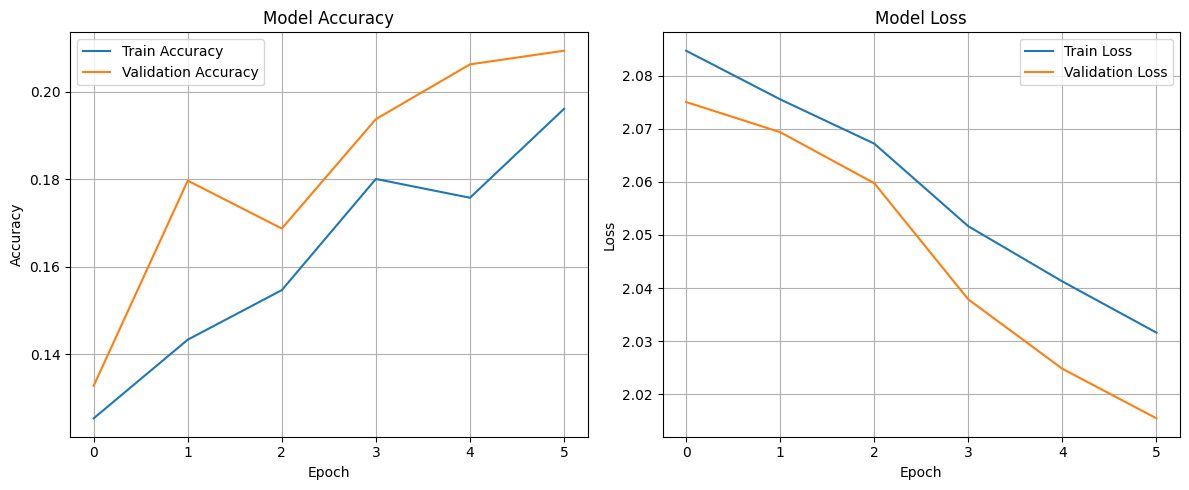

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Make Inference
For some unseen data, make predictions using the trained model.

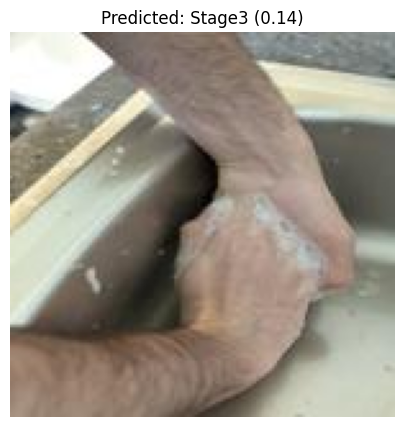

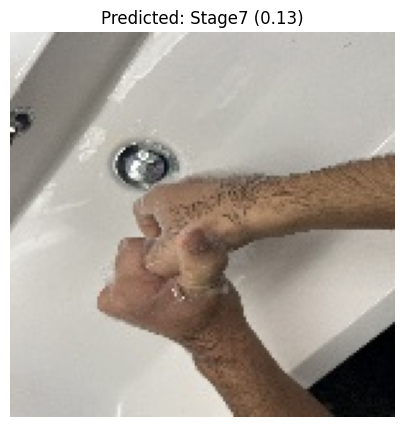

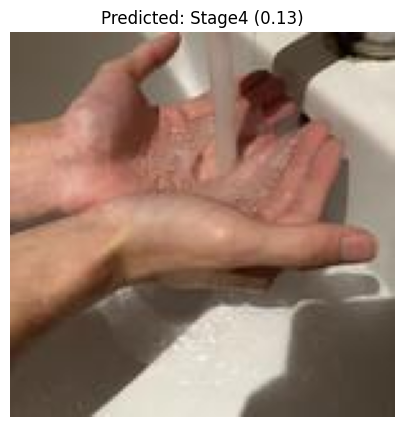

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

unseen_files = [
    "/content/drive/MyDrive/Colab Notebooks/CHS2406_Coursework2_Dataset_2526/CHS2406_Coursework2_Data_Repository/Stage5/stage_5_2452445_7.jpg",
    "/content/drive/MyDrive/Colab Notebooks/CHS2406_Coursework2_Dataset_2526/CHS2406_Coursework2_Data_Repository/Stage6/stage_6_U2363739_5.JPG",
    "/content/drive/MyDrive/Colab Notebooks/CHS2406_Coursework2_Dataset_2526/CHS2406_Coursework2_Data_Repository/Stage1/Stage_1_U2553802_03.jpg",

]

for fp in unseen_files:

    img = Image.open(fp).convert('RGB').resize((IMG_H, IMG_W))

    arr = np.array(img)
    arr_proc = mobilenet_preprocess(arr)
    arr_proc = np.expand_dims(arr_proc, axis=0)

    preds = model.predict(arr_proc, verbose=0)
    class_idx = np.argmax(preds)
    class_label = classes[class_idx]
    prob = np.max(preds)

    plt.figure(figsize=(5,5))
    plt.imshow(arr)
    plt.title(f"Predicted: {class_label} ({prob:.2f})")
    plt.axis('off')
    plt.show()


Lastly, the trained model was tested on several unseen images at various stages of handwashing. The images were preprocessed to fit the model input requirements. The predictions and their confidence scores were received and visualized with matplotlib. The step shows that the model can be used to generalize to new data and correctly categorize handwashing phases, which is why it could be used in the real world to monitor hygiene compliance